# Black-Scholes PINN Implementation

In this notebook, I implement a Physics-Informed Neural Network (PINN) to approximate the solution of the Black-Scholes PDE for a European call option.

The aim is to train a neural network to learn the option price $V(S,\tau)$, where:

- $S$ is the stock price
- $\tau$ is the time to maturity
- $V(S,\tau)$ is the option value

I use the transformation

$$
\tau = T - t,
$$

so the Black-Scholes PDE is written in forward time-to-maturity form as

$$
\frac{\partial V}{\partial \tau}
=
\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ rS \frac{\partial V}{\partial S}
- rV.
$$

The PINN takes the input pair $(S,\tau)$ and outputs an approximation to the option price $V(S,\tau)$.

The model is trained by minimizing a loss function made up of four terms:

1. PDE loss: measures how well the neural network satisfies the Black-Scholes PDE inside the domain.
2. Lower boundary loss: enforces the option price at the lower stock price boundary.
3. Upper boundary loss: enforces the option price at the upper stock price boundary.
4. Initial payoff loss: enforces the European call payoff at $\tau = 0$.

For a European call option, the payoff condition is

$$
V(S,0) = \max(S-K,0).
$$

The boundary conditions used are

$$
V(0,\tau) = 0,
$$

and

$$
V(S_{\max},\tau) = S_{\max} - Ke^{-r\tau}.
$$

The fixed parameter set used in this notebook is:

- Strike price: $K = 100$
- Maturity: $T = 1$
- Risk-free rate: $r = 0.05$
- Volatility: $\sigma = 0.2$
- Upper stock price boundary: $S_{\max} = 3K$

Once the PINN is trained, I compare its predicted option prices against the analytical Black-Scholes solution.

In [1]:
import sys
sys.path.append("..")

import torch
import numpy as np
import matplotlib.pyplot as plt
import gc
from src.metrics import error_summary
import pandas as pd

torch.set_num_threads(1)

from src.analytical import black_scholes_call_grid
from src.pinn import BlackScholesPINN
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss

torch.manual_seed(42)
np.random.seed(42)


In [2]:
# Defining parameters.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [3]:
# Training the PINN model.

model = BlackScholesPINN(
    layers=[2, 32, 32, 32, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_history = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200

def train_step():
    training_data = generate_training_points(N_f=N_f,N_ic=N_ic,N_bc=N_bc,S_max=S_max,T=T,K=K,r=r)

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(model,training_data,r=r,sigma=sigma,K=K)

    total_loss.backward()
    optimizer.step()

    values = (total_loss.detach().item(),loss_pde.detach().item(),loss_ic.detach().item(),loss_lb.detach().item(),loss_ub.detach().item())

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}")

Epoch 0: Total=5.746048e+00, PDE=9.594276e-05, IC=9.548487e-01, LB=1.568664e-02, UB=4.775417e+00
Epoch 500: Total=2.645917e-02, PDE=4.145956e-03, IC=1.769160e-02, LB=3.981474e-03, UB=6.401471e-04
Epoch 1000: Total=6.365833e-03, PDE=1.368964e-03, IC=4.317802e-03, LB=4.430297e-04, UB=2.360378e-04
Epoch 1500: Total=1.719636e-03, PDE=4.924156e-04, IC=1.027140e-03, LB=4.538425e-05, UB=1.546959e-04
Epoch 2000: Total=4.649391e-04, PDE=2.449721e-04, IC=1.893303e-04, LB=1.077457e-05, UB=1.986207e-05
Epoch 2500: Total=2.977890e-04, PDE=1.040961e-04, IC=1.760996e-04, LB=1.193967e-05, UB=5.653665e-06
Epoch 3000: Total=2.470640e-04, PDE=4.994071e-05, IC=1.802168e-04, LB=1.431508e-05, UB=2.591466e-06
Epoch 3500: Total=1.616443e-04, PDE=4.290344e-05, IC=1.107782e-04, LB=6.426660e-06, UB=1.536059e-06
Epoch 4000: Total=1.692005e-04, PDE=4.502411e-05, IC=1.183524e-04, LB=3.859268e-06, UB=1.964642e-06
Epoch 4500: Total=1.351577e-04, PDE=3.648893e-05, IC=9.138312e-05, LB=1.952215e-06, UB=5.333458e-06


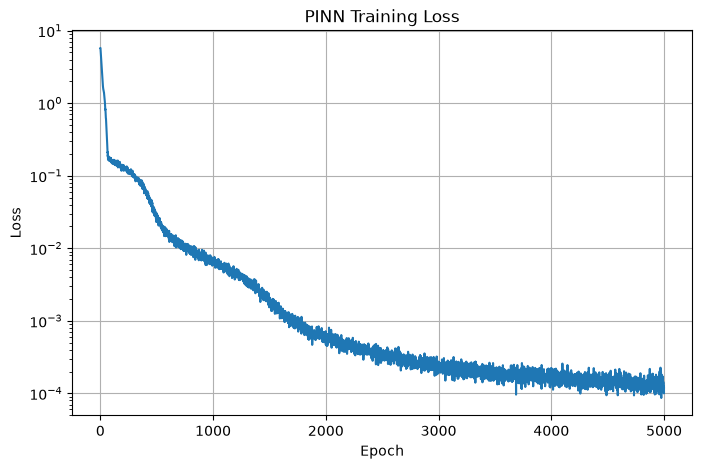

In [4]:
# Visualizing the training loss history.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Loss")
plt.grid(True)
plt.show()

In [5]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model.eval()
with torch.no_grad():
    V_pred = model(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

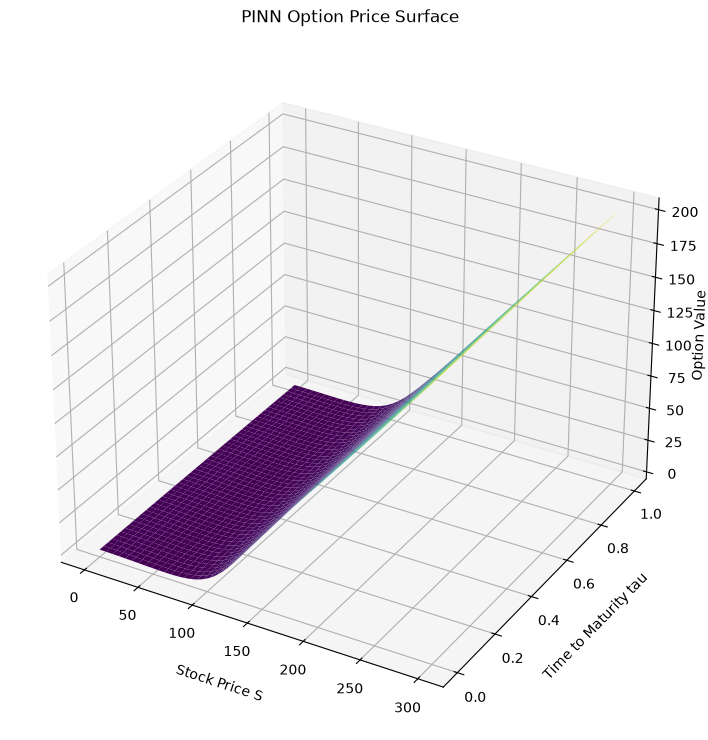

In [6]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface, cmap="viridis")

ax.set_title("PINN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

In [7]:
# Then apply this function to the same grid of stock prices and times to maturity used for the PINN evaluation, and compute the analytical option prices.

V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)

# Checking that the shapes of the PINN predictions and the analytical solution match, which is important for comparison and visualization.
print(V_surface.shape)
print(V_exact_surface.shape)

abs_error_surface = np.abs(V_surface - V_exact_surface)

(100, 50)
(100, 50)


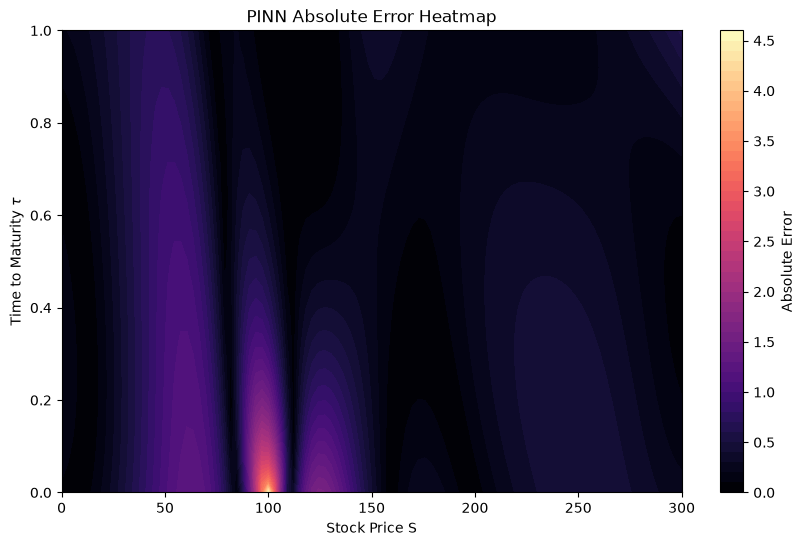

In [8]:
# Now, plot the absolute error heatmap between the PINN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [9]:
# Plotting some key metrics for a more quantitative assessment of the PINN's performance against the analytical solution.

metrics = error_summary(V_surface, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.250624
1,RMSE,0.500623
2,MAE,0.363268
3,Max Abs Error,4.505993
4,Relative L2 Error,0.005180


The maximum absolute error occurs near the strike price $K=100$ and $\tau = 0$. An EU call payoff has a kink at this point which the PINN struggles to deal with given it uses smooth $\tanh()$ activation functions. Away from this point the error is much smaller.

## Tuning PINN

Here I will do some basic tuning to see if I can improve performance. 

* First I wll tune the architecture by increasing the number of neurons (i.e using a wider network).
* Then I will add a learning rate scheduler.
* Then I will increase the weight of the initial condition loss in my loss function, since this is the point where the max loss is achieved.

In [10]:
# Tuned PINN: wider network.

model_wide = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide = torch.optim.Adam(model_wide.parameters(), lr=1e-3)

loss_history_wide = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_wide.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_wide,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer_wide.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide()

    loss_history_wide.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=4.671806e+00, PDE=3.395728e-03, IC=7.545945e-01, LB=1.060458e-02, UB=3.903211e+00
Epoch 500: Total=7.311921e-03, PDE=2.070575e-03, IC=4.557430e-03, LB=5.239185e-04, UB=1.599970e-04
Epoch 1000: Total=1.014384e-03, PDE=3.804693e-04, IC=5.376735e-04, LB=3.298229e-05, UB=6.325878e-05
Epoch 1500: Total=7.119766e-04, PDE=1.253384e-04, IC=5.522131e-04, LB=2.587789e-05, UB=8.547215e-06
Epoch 2000: Total=6.109659e-04, PDE=1.012153e-04, IC=4.798662e-04, LB=1.683680e-05, UB=1.304766e-05
Epoch 2500: Total=4.526462e-04, PDE=9.907460e-05, IC=3.069926e-04, LB=1.032826e-05, UB=3.625077e-05
Epoch 3000: Total=3.282440e-04, PDE=9.694707e-05, IC=2.043734e-04, LB=2.205485e-05, UB=4.868695e-06
Epoch 3500: Total=7.167305e-04, PDE=6.124555e-05, IC=3.547818e-04, LB=6.891935e-05, UB=2.317838e-04
Epoch 4000: Total=4.877907e-04, PDE=4.358066e-05, IC=3.173945e-04, LB=4.649342e-05, UB=8.032210e-05
Epoch 4500: Total=2.551923e-04, PDE=2.799436e-05, IC=1.452574e-04, LB=1.168505e-05, UB=7.025542e-05


In [11]:
# Create evaluation grid for tuned model.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide.eval()
with torch.no_grad():
    V_pred = model_wide(S_flat, tau_flat)

V_surface_modified = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

modified_abs_error_surface = np.abs(V_surface_modified - V_exact_surface)


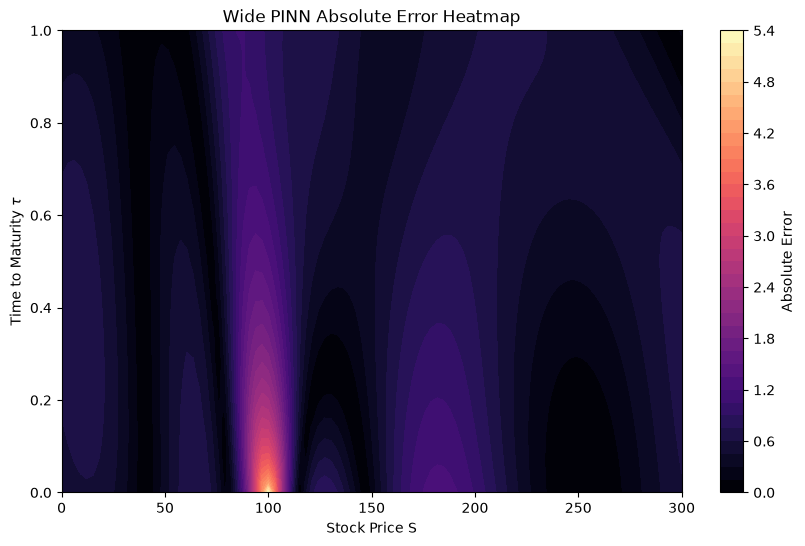

In [12]:
# Generating an error heatmap for the tuned model to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, modified_abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("Wide PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [13]:
# Plotting some key metrics for a more quantitative assessment of the tuned PINN's performance against the analytical solution.

metrics_wide = error_summary(V_surface_modified, V_exact_surface)

metrics_wide_table = pd.DataFrame({
    "Metric": metrics_wide.keys(),
    "Value": metrics_wide.values()
})

metrics_wide_table

,Metric,Value
0,MSE,0.482299
1,RMSE,0.694477
2,MAE,0.562019
3,Max Abs Error,5.379873
4,Relative L2 Error,0.007186


In [14]:
# Tuned PINN: wider network with learning rate scheduler.

model_wide_scheduler = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide_scheduler = torch.optim.Adam(
    model_wide_scheduler.parameters(),
    lr=1e-3
)

scheduler_wide = torch.optim.lr_scheduler.StepLR(
    optimizer_wide_scheduler,
    step_size=2000,
    gamma=0.5
)

loss_history_wide_scheduler = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide_scheduler():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_wide_scheduler.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_wide_scheduler,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer_wide_scheduler.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide_scheduler()

    scheduler_wide.step()

    loss_history_wide_scheduler.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_wide_scheduler.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=5.467763e+00, PDE=2.307883e-04, IC=9.969002e-01, LB=1.089952e-02, UB=4.459733e+00, LR=1.00e-03
Epoch 500: Total=8.748213e-03, PDE=1.463805e-03, IC=6.165257e-03, LB=7.410347e-04, UB=3.781157e-04, LR=1.00e-03
Epoch 1000: Total=1.929600e-03, PDE=5.018480e-04, IC=1.278661e-03, LB=3.727964e-05, UB=1.118109e-04, LR=1.00e-03
Epoch 1500: Total=9.064821e-04, PDE=2.519033e-04, IC=5.950353e-04, LB=3.203072e-05, UB=2.751279e-05, LR=1.00e-03
Epoch 2000: Total=8.272527e-04, PDE=1.707301e-04, IC=6.159834e-04, LB=1.523326e-05, UB=2.530597e-05, LR=5.00e-04
Epoch 2500: Total=6.484581e-04, PDE=1.554714e-04, IC=4.555532e-04, LB=3.192297e-05, UB=5.510511e-06, LR=5.00e-04
Epoch 3000: Total=7.167257e-04, PDE=1.371828e-04, IC=5.231297e-04, LB=3.115265e-05, UB=2.526057e-05, LR=5.00e-04
Epoch 3500: Total=5.814662e-04, PDE=1.167307e-04, IC=4.344834e-04, LB=1.939808e-05, UB=1.085402e-05, LR=5.00e-04
Epoch 4000: Total=4.073631e-04, PDE=1.178950e-04, IC=2.437955e-04, LB=3.834423e-05, UB=7.328420e-06,

In [15]:
# Create evaluation grid for model with learning rate scheduler.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide_scheduler.eval()
with torch.no_grad():
    V_pred = model_wide_scheduler(S_flat, tau_flat)

V_surface_scheduler = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

abs_error_surface_scheduler = np.abs(V_surface_scheduler - V_exact_surface)


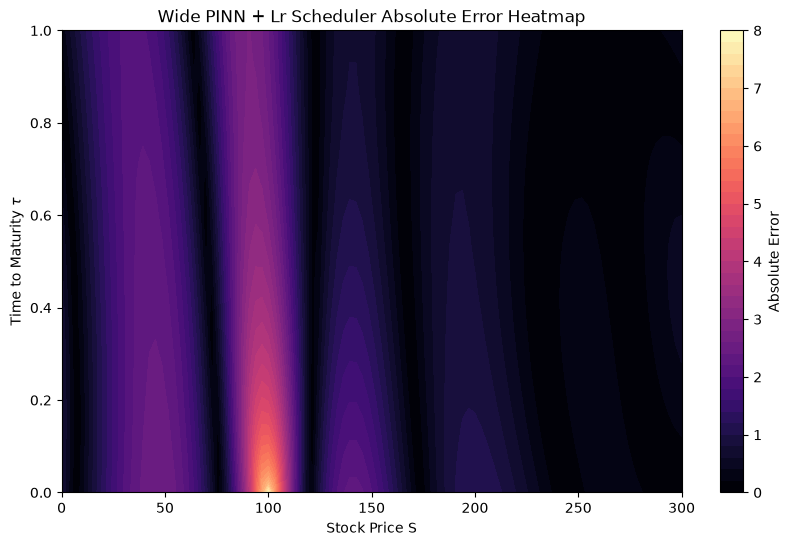

In [16]:
# Generating an error heatmap for the model with learning rate scheduler to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_scheduler, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("Wide PINN + Lr Scheduler Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [17]:
# Plotting some key metrics for a more quantitative assessment of the PINN with learning rate scheduler's performance against the analytical solution.

metrics_wide_scheduler = error_summary(V_surface_scheduler, V_exact_surface)

metrics_wide_scheduler_table = pd.DataFrame({
    "Metric": metrics_wide_scheduler.keys(),
    "Value": metrics_wide_scheduler.values()
})

metrics_wide_scheduler_table

,Metric,Value
0,MSE,1.963900
1,RMSE,1.401392
2,MAE,0.992939
3,Max Abs Error,7.813058
4,Relative L2 Error,0.014500


In [18]:
model_wide_scheduler_modified_loss = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_modified = torch.optim.Adam(model_wide_scheduler_modified_loss.parameters(), lr=1e-3)

scheduler_modified = torch.optim.lr_scheduler.StepLR(
    optimizer_modified,
    step_size=2000,
    gamma=0.5
)

loss_history_modified = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_modified():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_modified.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_wide_scheduler_modified_loss,
        training_data,
        r=r,
        sigma=sigma,
        K=K,
        weight_ic=5.0
    )

    total_loss.backward()
    optimizer_modified.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_modified()

    scheduler_modified.step()

    loss_history_modified.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_modified.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=8.991997e+00, PDE=1.155914e-02, IC=9.923272e-01, LB=9.803690e-04, UB=4.017821e+00, LR=1.00e-03
Epoch 500: Total=1.431111e-02, PDE=2.067275e-03, IC=2.240288e-03, LB=3.875425e-04, UB=6.548468e-04, LR=1.00e-03
Epoch 1000: Total=2.891003e-03, PDE=4.184056e-04, IC=4.605658e-04, LB=1.190281e-04, UB=5.074037e-05, LR=1.00e-03
Epoch 1500: Total=1.249156e-03, PDE=1.305309e-04, IC=2.120568e-04, LB=4.864779e-05, UB=9.693429e-06, LR=1.00e-03
Epoch 2000: Total=7.604391e-04, PDE=1.025112e-04, IC=1.290337e-04, LB=9.607568e-06, UB=3.151774e-06, LR=5.00e-04
Epoch 2500: Total=6.150133e-04, PDE=9.424480e-05, IC=1.003172e-04, LB=8.191392e-06, UB=1.099112e-05, LR=5.00e-04
Epoch 3000: Total=4.739420e-04, PDE=8.271918e-05, IC=7.519501e-05, LB=1.038455e-05, UB=4.863189e-06, LR=5.00e-04
Epoch 3500: Total=5.020069e-04, PDE=9.902099e-05, IC=7.856411e-05, LB=8.109657e-06, UB=2.055729e-06, LR=5.00e-04
Epoch 4000: Total=6.788759e-04, PDE=8.945839e-05, IC=1.048518e-04, LB=3.664969e-05, UB=2.850898e-05,

In [19]:
# Create evaluation grid for wider model with lr scheduler and modified loss function.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide_scheduler_modified_loss.eval()
with torch.no_grad():
    V_pred = model_wide_scheduler_modified_loss(S_flat, tau_flat)

V_surface_wide_scheduler_modified_loss = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

abs_error_surface_wide_scheduler_modified_loss = np.abs(V_surface_wide_scheduler_modified_loss - V_exact_surface)


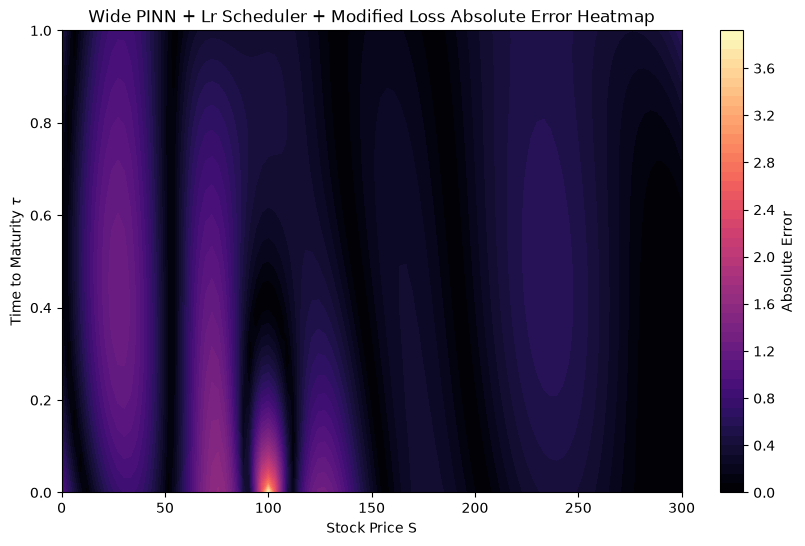

In [20]:
# Generating an error heatmap for the wide model with lr scheduler and modified loss function to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_wide_scheduler_modified_loss, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("Wide PINN + Lr Scheduler + Modified Loss Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [22]:
# Plotting some key metrics for a more quantitative assessment of the wide PINN with lr scheduler and modified loss function's performance against the analytical solution.

metrics_wide_scheduler_modified_loss = error_summary(V_surface_wide_scheduler_modified_loss, V_exact_surface)

metrics_wide_scheduler_modified_loss_table = pd.DataFrame({
    "Metric": metrics_wide_scheduler_modified_loss.keys(),
    "Value": metrics_wide_scheduler_modified_loss.values()
})

metrics_wide_scheduler_modified_loss_table

,Metric,Value
0,MSE,0.298793
1,RMSE,0.546620
2,MAE,0.429870
3,Max Abs Error,3.887356
4,Relative L2 Error,0.005656


The original PINN architecture performed best, however using the modified loss function did improve performance, particulary with the initial condition loss. I will perform one last experiment implementing the original PINN architecture with this new modified loss function.

In [21]:
# Training the original PINN architecture with modified loss.

model_mod_loss = BlackScholesPINN(
    layers=[2, 32, 32, 32, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_mod_loss = torch.optim.Adam(model_mod_loss.parameters(), lr=1e-3)

loss_history_mod_loss = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_mod_loss():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_mod_loss.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_mod_loss,
        training_data,
        r=r,
        sigma=sigma,
        K=K,
        weight_ic=5.0
    )

    total_loss.backward()
    optimizer_mod_loss.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_mod_loss()

    loss_history_mod_loss.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=8.549913e+00, PDE=1.011510e-02, IC=8.550415e-01, LB=3.312289e-03, UB=4.261278e+00
Epoch 500: Total=4.492205e-02, PDE=5.223518e-03, IC=6.662258e-03, LB=5.943207e-03, UB=4.440366e-04
Epoch 1000: Total=1.831288e-02, PDE=2.581729e-03, IC=2.873258e-03, LB=4.934099e-04, UB=8.714478e-04
Epoch 1500: Total=8.116364e-03, PDE=1.786029e-03, IC=1.149436e-03, LB=4.440496e-05, UB=5.387489e-04
Epoch 2000: Total=3.061117e-03, PDE=3.013083e-04, IC=5.128709e-04, LB=9.799586e-05, UB=9.745868e-05
Epoch 2500: Total=1.855345e-03, PDE=1.455135e-04, IC=3.269903e-04, LB=3.680078e-05, UB=3.807880e-05
Epoch 3000: Total=7.741470e-04, PDE=1.335349e-04, IC=1.232163e-04, LB=1.976070e-05, UB=4.769844e-06
Epoch 3500: Total=6.386519e-04, PDE=1.295064e-04, IC=9.918549e-05, LB=4.392071e-06, UB=8.826046e-06
Epoch 4000: Total=3.911277e-04, PDE=9.515436e-05, IC=5.664161e-05, LB=8.014137e-06, UB=4.751092e-06
Epoch 4500: Total=4.482525e-04, PDE=6.414741e-05, IC=6.566891e-05, LB=4.333900e-06, UB=5.142672e-05


In [23]:
# Create evaluation grid for wider model with  modified loss function.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide_scheduler_modified_loss.eval()
with torch.no_grad():
    V_pred = model_mod_loss(S_flat, tau_flat)

V_surface_mod_loss = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

abs_error_surface_mod_loss = np.abs(V_surface_mod_loss - V_exact_surface)


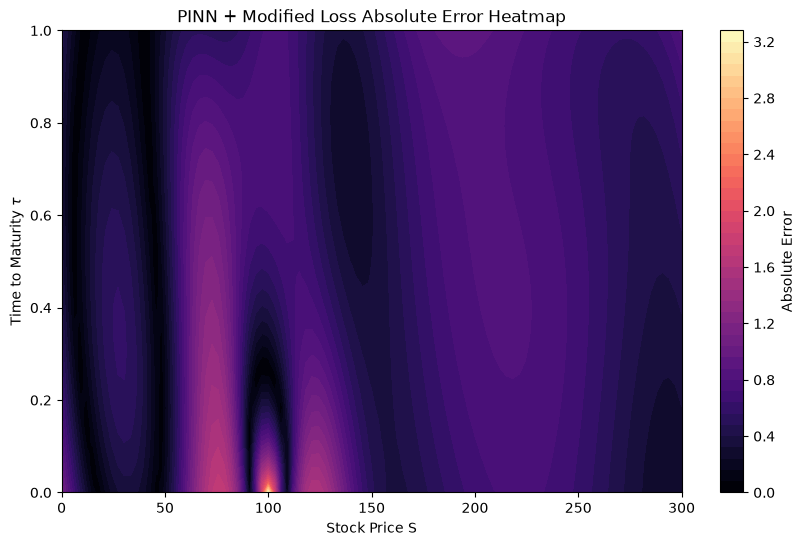

In [24]:
# Generating an error heatmap for the model with modified loss function to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_mod_loss, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN + Modified Loss Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [25]:
# Plotting some key metrics for a more quantitative assessment of the PINN with modified loss function's performance against the analytical solution.

metrics_mod_loss = error_summary(V_surface_mod_loss, V_exact_surface)

metrics_mod_loss_table = pd.DataFrame({
    "Metric": metrics_mod_loss.keys(),
    "Value": metrics_mod_loss.values()
})

metrics_mod_loss_table

,Metric,Value
0,MSE,0.427081
1,RMSE,0.653515
2,MAE,0.590918
3,Max Abs Error,3.244408
4,Relative L2 Error,0.006762


In [26]:
# Generate a comparison table for the different PINN models.

from src.evaluation import compute_metric_row

comparison_rows = [
    compute_metric_row(
        model_name="Baseline PINN",
        model=model,
        architecture="[2, 32, 32, 32, 1]",
        scheduler="No",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN",
        model=model_wide,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="No",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN + LR Scheduler",
        model=model_wide_scheduler,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN + Lr Scheduler + Modified Loss",
        model=model_wide_scheduler_modified_loss,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Weighted IC",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),

    compute_metric_row(
        model_name="PINN + Modified Loss",
        model=model_mod_loss,
        architecture="[2, 32, 32, 32, 1]",
        scheduler="No",
        loss_type="Weighted IC",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    )
]

comparison_table = pd.DataFrame(comparison_rows)

comparison_table

,Model,Architecture,Scheduler,Loss,MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Baseline PINN,"[2, 32, 32, 32, 1]",No,Standard,0.250624,0.500623,0.363268,4.505993,0.005180
1,Wider PINN,"[2, 64, 64, 64, 1]",No,Standard,0.482299,0.694477,0.562019,5.379873,0.007186
2,Wider PINN + LR Scheduler,"[2, 64, 64, 64, 1]",StepLR,Standard,1.963900,1.401392,0.992939,7.813058,0.014500
3,Wider PINN + Lr Scheduler + Modified Loss,"[2, 64, 64, 64, 1]",StepLR,Weighted IC,0.298793,0.546620,0.429870,3.887356,0.005656
4,PINN + Modified Loss,"[2, 32, 32, 32, 1]",No,Weighted IC,0.427081,0.653515,0.590918,3.244408,0.006762


In [45]:
# Defining a function that counts the number of trainable parameters in a given model architecture.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model_mod_loss)

2241

The PINN with modified loss function performed best on all metrics except MAE. This is the model I will use in further comparisons with PIKANs.